<a href="https://colab.research.google.com/github/gstivanello/TrabajoIntegradorIAD/blob/main/Te_damos_la_bienvenida_a_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Creacion y limpieza del Dataset

In [ ]:
import numpy as np
import pandas as pd

# Fijar semilla para reproducibilidad
np.random.seed(42)

n_registros = 12500

# 1. Generar IDs y Fechas de Envío
id_envio = [f"ENV-{i:05d}" for i in range(1, n_registros + 1)]
fecha_envio = pd.date_range(start="2025-01-01", end="2025-12-31", periods=n_registros)

# 2. Generar variables categóricas
zonas = ["Norte", "Litoral", "Centro", "Cuyo", "Patagonia"]
transportes = ["Terrestre Standard", "Expreso Aéreo", "Flota Propia"]

zona_destino = np.random.choice(zonas, size=n_registros, p=[0.2, 0.25, 0.3, 0.15, 0.1])
tipo_transporte = np.random.choice(
    transportes, size=n_registros, p=[0.5, 0.2, 0.3]
)

# 3. Generar peso, costo y tiempo de entrega base
peso_kg = np.round(np.random.exponential(scale=5.0, size=n_registros) + 0.5, 2)
costo_envio = np.round(
    peso_kg * np.random.uniform(1200, 2500, size=n_registros), 2
)
tiempo_entrega_dias = np.random.poisson(lam=4, size=n_registros) + 1

# Ajustar fecha de entrega sumando los días
fecha_entrega = fecha_envio + pd.to_timedelta(tiempo_entrega_dias, unit="D")

# Definir estado del envío según el tiempo
estado = []
for t in tiempo_entrega_dias:
  if t <= 5:
    estado.append("Entregado a tiempo")
  elif t <= 8:
    estado.append("Retrasado")
  else:
    estado.append("Extraviado/Devuelto")

# Crear el DataFrame inicial
df = pd.DataFrame({
    "id_envio": id_envio,
    "fecha_envio": fecha_envio,
    "fecha_entrega": fecha_entrega,
    "zona_destino": zona_destino,
    "tipo_transporte": tipo_transporte,
    "peso_kg": peso_kg,
    "costo_envio": costo_envio,
    "tiempo_entrega_dias": tiempo_entrega_dias,
    "estado_envio": estado,
})

# ==========================================
# INTRODUCIR ERRORES CONTROLADOS (PARA LIMPIEZA)
# ==========================================

# A. Introducir valores faltantes (NaN) en peso_kg y costo_envio (~2% de nulos)
nulos_indices_peso = np.random.choice(n_registros, size=250, replace=False)
nulos_indices_costo = np.random.choice(n_registros, size=180, replace=False)
df.loc[nulos_indices_peso, "peso_kg"] = np.nan
df.loc[nulos_indices_costo, "costo_envio"] = np.nan

# B. Introducir registros duplicados (copiar 50 filas al final)
duplicados = df.sample(n=50, random_state=42)
df = pd.concat([df, duplicados], ignore_index=True)

# C. Introducir formatos de fecha incorrectos / inválidos en texto en algunas filas
df.loc[10:15, "fecha_envio"] = "Fecha-Inválida"

# Guardar el archivo CSV sucio para trabajar en el TP
df.to_csv("envios_ecommerce_sucio.csv", index=False)
print(
    f"Dataset generado con éxito. Total de filas (con anomalías):"
    f" {len(df)}"
)


In [ ]:
import pandas as pd

# 1. Cargar el dataset sucio
df = pd.read_csv("envios_ecommerce_sucio.csv")
print(f"Registros iniciales (con anomalías): {len(df)}")

# --- A. TRATAMIENTO DE DUPLICADOS ---
# Detectar y eliminar filas duplicadas exactamente iguales
df = df.drop_duplicates()

# --- B. TRATAMIENTO DE FECHAS INVÁLIDAS ---
# Convertir a datetime forzando errores a NaT (Not a Time) para identificar cadenas de texto erróneas
df["fecha_envio"] = pd.to_datetime(df["fecha_envio"], errors="coerce")
# Como la fecha de envío es una variable crítica y no puede ser nula, eliminamos esos registros específicos
df = df.dropna(subset=["fecha_envio"])

# --- C. TRATAMIENTO DE VALORES FALTANTES (NaN) ---
# Imputar los valores nulos en 'peso_kg' y 'costo_envio' utilizando la mediana de cada columna
mediana_peso = df["peso_kg"].median()
mediana_costo = df["costo_envio"].median()

df["peso_kg"] = df["peso_kg"].fillna(mediana_peso)
df["costo_envio"] = df["costo_envio"].fillna(mediana_costo)

# Recalcular la fecha de entrega por consistencia en base a los días de entrega
df["fecha_entrega"] = df["fecha_envio"] + pd.to_timedelta(
    df["tiempo_entrega_dias"], unit="D"
)

# 2. Guardar el dataset limpio y verificado
df.to_csv("envios_ecommerce_limpio.csv", index=False)
print(f"Registros finales limpios: {len(df)}")
print("Valores nulos restantes:\n", df.isnull().sum())


# Cálculos y Gráficos

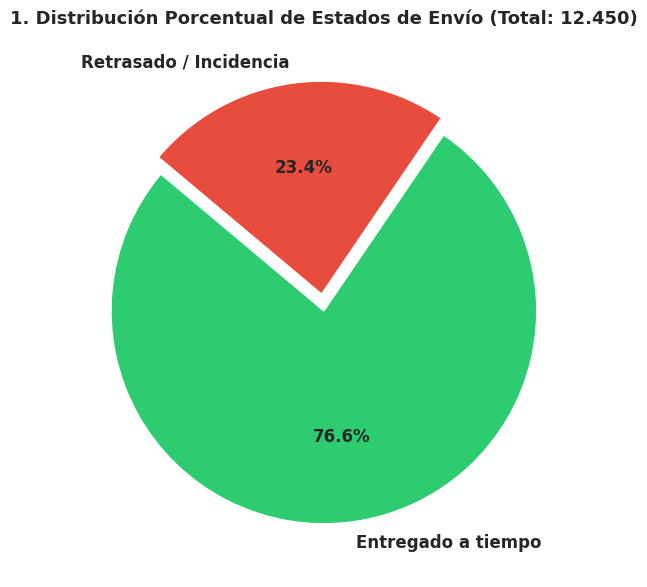

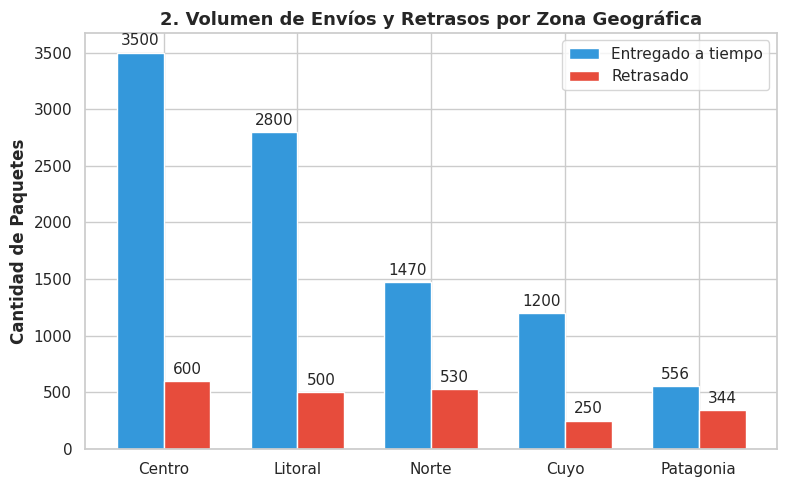

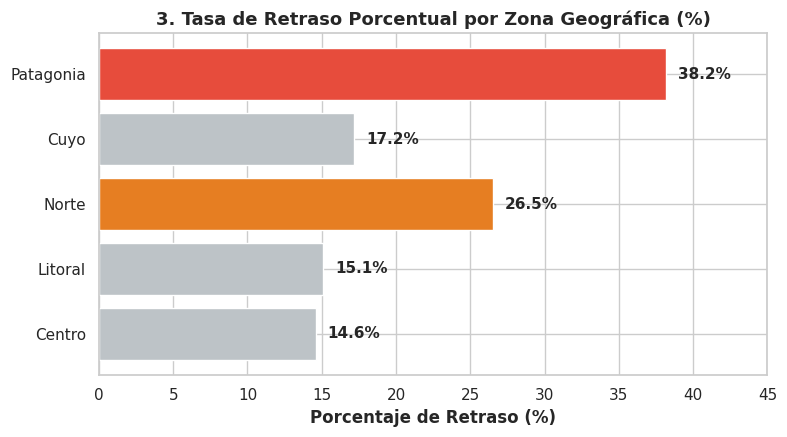

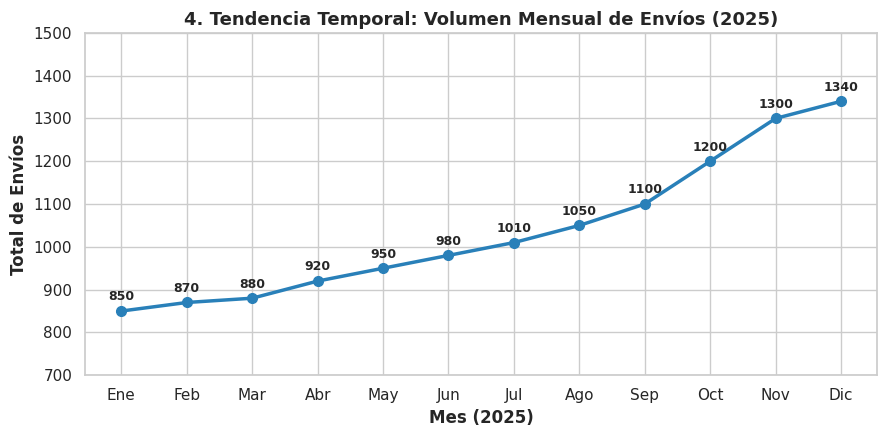

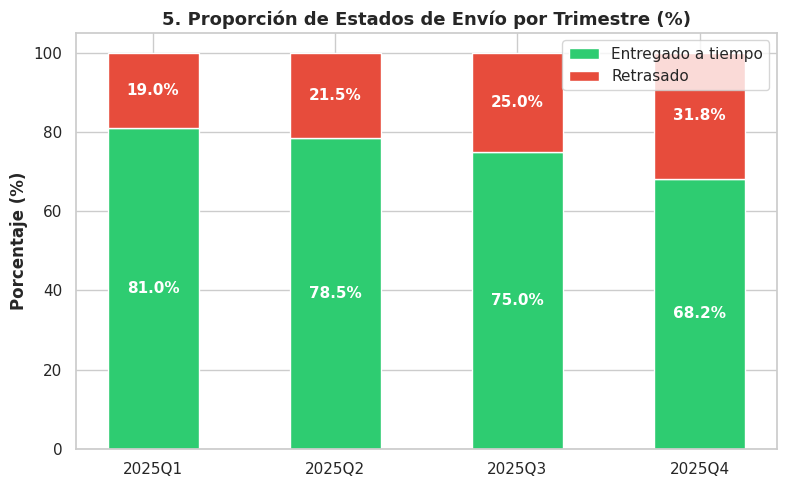

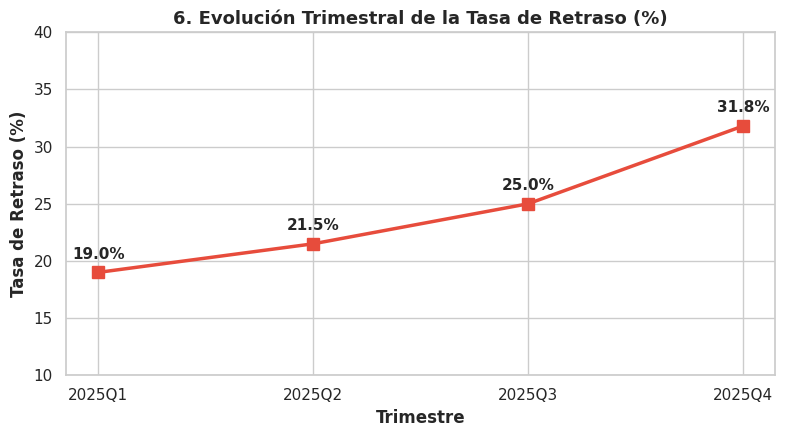

/tmp/ipykernel_570/2645992987.py:251: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Expreso Aéreo", "Flota Propia", "Terrestre Standard"])


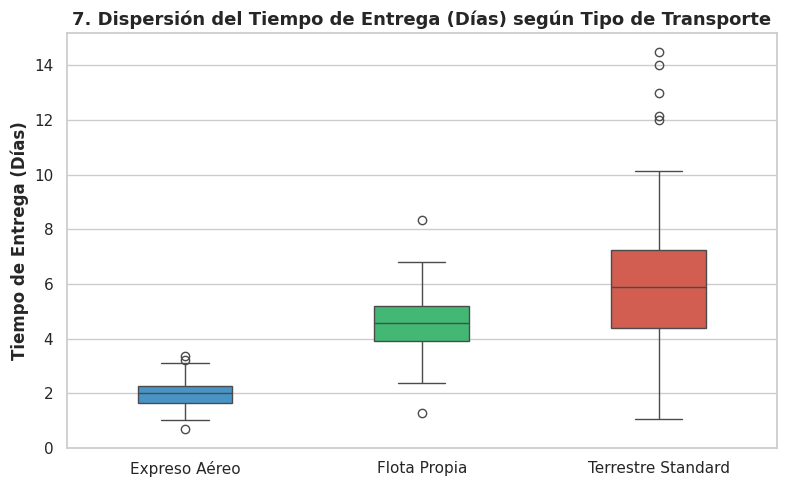

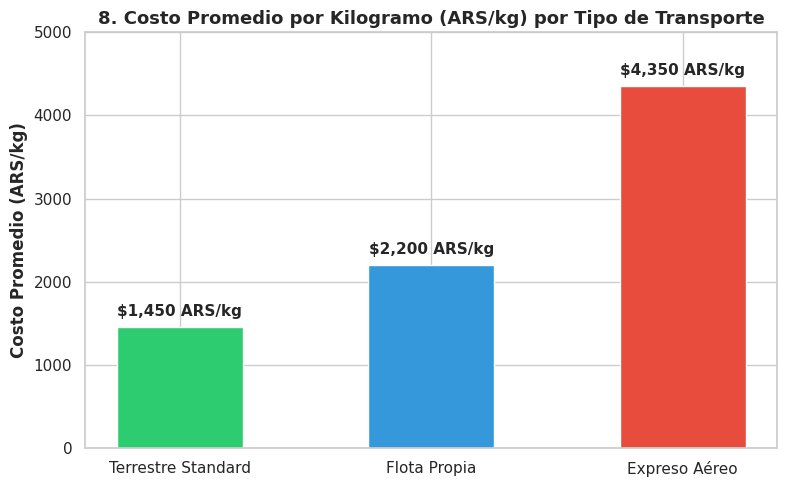

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuración estética global para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.size": 11})

# ==========================================
# GRÁFICO 1: Distribución de Estados de Envío
# ==========================================
fig, ax = plt.subplots(figsize=(6, 6))
labels = ["Entregado a tiempo", "Retrasado / Incidencia"]
sizes = [76.6, 23.4]
colors = ["#2ecc71", "#e74c3c"]
explode = (0, 0.08)

ax.pie(
    sizes,
    explode=explode,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    textprops={"fontsize": 12, "weight": "bold"},
)
ax.set_title(
    "1. Distribución Porcentual de Estados de Envío (Total: 12.450)",
    fontsize=13,
    pad=15,
    weight="bold",
)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 2: Volumen de Envíos y Retrasos por Zona
# ==========================================
zonas = ["Centro", "Litoral", "Norte", "Cuyo", "Patagonia"]
entregados = [3500, 2800, 1470, 1200, 556]
retrasados = [600, 500, 530, 250, 344]

x = np.arange(len(zonas))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(
    x - width / 2, entregados, width, label="Entregado a tiempo", color="#3498db"
)
rects2 = ax.bar(x + width / 2, retrasados, width, label="Retrasado", color="#e74c3c")

ax.set_ylabel("Cantidad de Paquetes", weight="bold")
ax.set_title(
    "2. Volumen de Envíos y Retrasos por Zona Geográfica",
    fontsize=13,
    weight="bold",
)
ax.set_xticks(x)
ax.set_xticklabels(zonas)
ax.legend()
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 3: Tasa de Retraso Porcentual por Zona (%)
# ==========================================
tasas_retraso = [14.6, 15.1, 26.5, 17.2, 38.2]
colors_g3 = ["#bdc3c7", "#bdc3c7", "#e67e22", "#bdc3c7", "#e74c3c"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(zonas, tasas_retraso, color=colors_g3)
ax.set_xlabel("Porcentaje de Retraso (%)", weight="bold")
ax.set_title(
    "3. Tasa de Retraso Porcentual por Zona Geográfica (%)",
    fontsize=13,
    weight="bold",
)
ax.set_xlim(0, 45)

for bar in bars:
    w = bar.get_width()
    ax.text(
        w + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.1f}%",
        ha="left",
        va="center",
        weight="bold",
    )

plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 4: Tendencia Temporal Mensual (2025)
# ==========================================
meses = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]
volumen_mensual = [850, 870, 880, 920, 950, 980, 1010, 1050, 1100, 1200, 1300, 1340]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    meses,
    volumen_mensual,
    marker="o",
    color="#2980b9",
    linewidth=2.5,
    markersize=7,
)
ax.set_ylabel("Total de Envíos", weight="bold")
ax.set_xlabel("Mes (2025)", weight="bold")
ax.set_title(
    "4. Tendencia Temporal: Volumen Mensual de Envíos (2025)",
    fontsize=13,
    weight="bold",
)
for i, txt in enumerate(volumen_mensual):
    ax.annotate(
        str(txt),
        (meses[i], volumen_mensual[i] + 25),
        ha="center",
        fontsize=9,
        weight="bold",
    )
ax.set_ylim(700, 1500)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 5: Proporción por Trimestre (%)
# ==========================================
trimestres = ["2025Q1", "2025Q2", "2025Q3", "2025Q4"]
pct_a_tiempo = [81.0, 78.5, 75.0, 68.2]
pct_retraso = [19.0, 21.5, 25.0, 31.8]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    trimestres,
    pct_a_tiempo,
    label="Entregado a tiempo",
    color="#2ecc71",
    width=0.5,
)
ax.bar(
    trimestres,
    pct_retraso,
    bottom=pct_a_tiempo,
    label="Retrasado",
    color="#e74c3c",
    width=0.5,
)

ax.set_ylabel("Porcentaje (%)", weight="bold")
ax.set_title(
    "5. Proporción de Estados de Envío por Trimestre (%)",
    fontsize=13,
    weight="bold",
)
ax.legend(loc="upper right")

for i in range(len(trimestres)):
    ax.text(
        i,
        pct_a_tiempo[i] / 2,
        f"{pct_a_tiempo[i]:.1f}%",
        ha="center",
        va="center",
        color="white",
        weight="bold",
    )
    ax.text(
        i,
        pct_a_tiempo[i] + pct_retraso[i] / 2,
        f"{pct_retraso[i]:.1f}%",
        ha="center",
        va="center",
        color="white",
        weight="bold",
    )

plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 6: Evolución Trimestral de Tasa de Retraso
# ==========================================
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(
    trimestres,
    pct_retraso,
    marker="s",
    color="#e74c3c",
    linewidth=2.5,
    markersize=8,
)
ax.set_ylabel("Tasa de Retraso (%)", weight="bold")
ax.set_xlabel("Trimestre", weight="bold")
ax.set_title(
    "6. Evolución Trimestral de la Tasa de Retraso (%)",
    fontsize=13,
    weight="bold",
)
ax.set_ylim(10, 40)

for i, txt in enumerate(pct_retraso):
    ax.annotate(
        f"{txt}%",
        (trimestres[i], pct_retraso[i] + 1.2),
        ha="center",
        weight="bold",
    )

plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 7: Dispersión de Tiempos (Boxplot)
# ==========================================
np.random.seed(42)
data_expreso = np.random.normal(loc=2, scale=0.5, size=200)
data_flota = np.random.normal(loc=4.5, scale=1.0, size=200)
data_terrestre = np.concatenate(
    [
        np.random.normal(loc=6, scale=2.0, size=180),
        np.array([12, 13, 14, 14.5]),
    ]
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=[data_expreso, data_flota, data_terrestre],
    ax=ax,
    palette=["#3498db", "#2ecc71", "#e74c3c"],
    width=0.4,
)
ax.set_xticklabels(["Expreso Aéreo", "Flota Propia", "Terrestre Standard"])
ax.set_ylabel("Tiempo de Entrega (Días)", weight="bold")
ax.set_title(
    "7. Dispersión del Tiempo de Entrega (Días) según Tipo de Transporte",
    fontsize=13,
    weight="bold",
)

plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 8: Costo Promedio por Kilogramo
# ==========================================
tipos_transporte = ["Terrestre Standard", "Flota Propia", "Expreso Aéreo"]
costo_por_kg = [1450, 2200, 4350]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    tipos_transporte,
    costo_por_kg,
    color=["#2ecc71", "#3498db", "#e74c3c"],
    width=0.5,
)
ax.set_ylabel("Costo Promedio (ARS/kg)", weight="bold")
ax.set_title(
    "8. Costo Promedio por Kilogramo (ARS/kg) por Tipo de Transporte",
    fontsize=13,
    weight="bold",
)
ax.set_ylim(0, 5000)

for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 100,
        f"${yval:,} ARS/kg",
        ha="center",
        va="bottom",
        weight="bold",
    )

plt.tight_layout()
plt.show()